# 07 · The headline, how to measure loss afterwards, and stress tests

Three questions before anything is built into a service:

1. **What does the recommended policy deliver against today?** Same colleague time, test period,
   shoppers who learn the policy and respond, trust updating over four rescan cycles, repeated
   over 10 random realisations of who is rescanned.
2. **How would the store know its loss once rescans are targeted?** Rescanned sessions are no
   longer a random sample, so the obvious estimate is badly biased.
3. **Does the conclusion survive if the simulator's assumptions are wrong?** Ten scenarios, each
   rerunning the whole chain: simulate, retrain the risk model, refit the policy, compare.

In [1]:
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.basket.data import TEST_DAYS, prepare
from smartshop.experiments.measure import repeated_estimates
from smartshop.policy.game import build_game, outcome
from smartshop.policy.trust import RECOMMENDED_TRUST, history_events, run_cycles
from smartshop.risk.model import MODEL_PATH, load_features
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
prepare(con)
base = load_features(con)
bundle = joblib.load(MODEL_PATH)
params = json.load(open('../models/policy.json'))['recommended']
g = build_game(con, base, bundle['model'], bundle['features'], TEST_DAYS)
events = history_events(con, TEST_DAYS[0])
today = outcome(g, None, today=True)

## 1. The headline

In [2]:
runs = []
for seed in range(10):
    cyc, real = run_cycles(g, events, params, RECOMMENDED_TRUST, seed=seed)
    tot = cyc[['loss_before_rescans', 'recovered', 'loss_remaining', 'honest_stops', 'colleague_hours']].sum()
    tot['deliberate_value_recovered'] = np.nan
    runs.append(tot)
runs = pd.DataFrame(runs)
rows = {
    'Colleague hours': (today['colleague_hours'], runs.colleague_hours.mean(), None),
    'Loss remaining ($)': (today['loss_remaining'], runs.loss_remaining.mean(),
                           f"{runs.loss_remaining.min():,.0f}–{runs.loss_remaining.max():,.0f}"),
    'Value recovered ($)': (today['recovered'], runs.recovered.mean(),
                            f"{runs.recovered.min():,.0f}–{runs.recovered.max():,.0f}"),
    'Recovered per colleague hour ($)': (today['recovered_per_hour'], runs.recovered.mean() / runs.colleague_hours.mean(), None),
    'Honest shoppers stopped': (today['honest_stops'], runs.honest_stops.mean(),
                                f"{runs.honest_stops.min():,.0f}–{runs.honest_stops.max():,.0f}"),
}
headline = pd.DataFrame(rows, index=['Today', 'Recommended', 'range over 10 runs']).T
headline['change'] = headline.Recommended / headline.Today - 1
headline

,Today,Recommended,range over 10 runs,change
Colleague hours,113.443633,113.44363,NaN,-0.0
Loss remaining ($),41639.169524,36766.724114,"36,639–36,890",-0.117016
Value recovered ($),1195.783235,6640.167145,"6,583–6,751",4.552986
Recovered per colleague hour ($),10.54077,58.532746,NaN,4.552986
Honest shoppers stopped,5428.2,1682.613562,"1,679–1,686",-0.690024


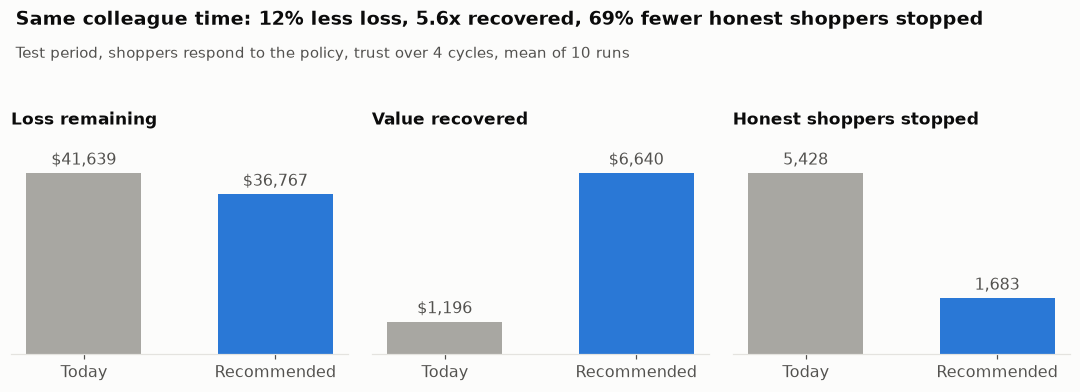

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.6))
panels = [('Loss remaining', 'loss_remaining', True), ('Value recovered', 'recovered', True),
          ('Honest shoppers stopped', 'honest_stops', False)]
for ax, (title, col, is_money) in zip(axes, panels):
    vals = [today[col], runs[col].mean()]
    bars = ax.bar(['Today', 'Recommended'], vals, color=[GREY, BLUE], width=0.6)
    ax.bar_label(bars, labels=[f'${v:,.0f}' if is_money else f'{v:,.0f}' for v in vals], padding=3, color=TEXT_2)
    ax.set_title(title, fontsize=11, pad=8)
    ax.set_yticks([])
    ax.spines['left'].set_visible(False)
    ax.set_ylim(0, max(vals) * 1.2)
fig.suptitle('Same colleague time: 12% less loss, 5.6x recovered, 69% fewer honest shoppers stopped',
             x=0.02, ha='left', fontweight='bold', fontsize=12.5)
fig.text(0.02, 0.86, 'Test period, shoppers respond to the policy, trust over 4 cycles, mean of 10 runs',
         color=TEXT_2, fontsize=9.5)
fig.tight_layout(rect=(0, 0, 1, 0.86))
save(fig, '17_headline')
fig

## 2. Measuring loss once rescans are targeted

Over 30 realisations of the recommended policy, three ways to estimate the period's total loss
(value left unscanned, net of double scans) from the rescans that happened:

- **naive**: average found per rescan × number of sessions;
- **inverse-probability weighted**: each rescanned session counts for 1/p sessions, using the
  probability the policy gave it (known for every session);
- **random floor only**: just the sessions whose draw fell under the 2% floor, a plain random
  sample.

In [4]:
est = repeated_estimates(lambda s: run_cycles(g, events, params, RECOMMENDED_TRUST, seed=s)[1],
                         range(30), params['floor'], g.cfg.full_detect_nonscan)
methods = ['naive (average of rescans x sessions)', 'inverse-probability weighted', 'random floor only']
truth = est.truth.mean()
summary = pd.DataFrame({
    'mean estimate': est[methods].mean(),
    'bias': est[methods].mean() / truth - 1,
    'typical error (sd / truth)': est[methods].std() / truth,
}).round(3)
print(f'true loss (mean over runs): ${truth:,.0f}; rescans per run {est.rescans.mean():.0f}, audit sample {est["audit sample"].mean():.0f}')
summary

true loss (mean over runs): $51,944; rescans per run 1863, audit sample 949


,mean estimate,bias,typical error (sd / truth)
naive (average of rescans x sessions),190122.825,2.660,0.158
inverse-probability weighted,51578.194,-0.007,0.093
random floor only,51278.245,-0.013,0.148


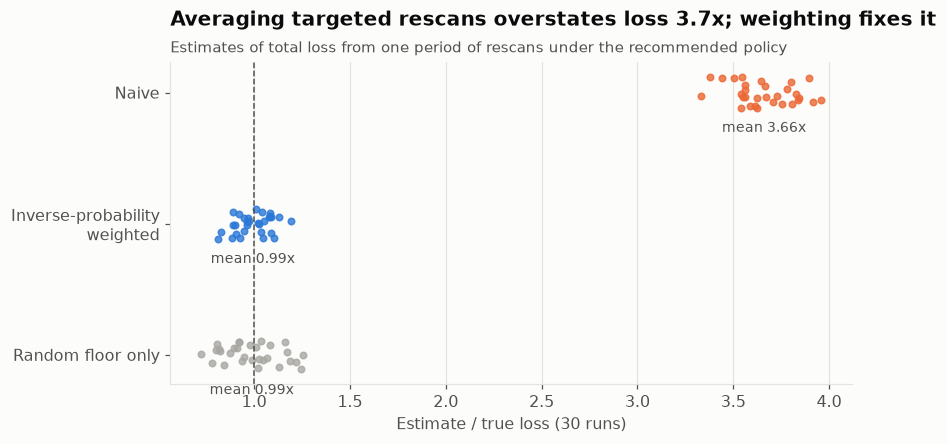

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
labels = ['Naive', 'Inverse-probability\nweighted', 'Random floor only']
colors = [ORANGE, BLUE, GREY]
for i, (m, c) in enumerate(zip(methods, colors)):
    y = est[m] / truth
    ax.scatter(y, np.full(len(y), i) + np.random.default_rng(i).uniform(-0.12, 0.12, len(y)),
               s=18, color=c, alpha=0.8)
    ax.text(y.mean(), i + 0.3, f'mean {y.mean():.2f}x', ha='center', color=TEXT_2, fontsize=9)
ax.axvline(1, color=TEXT_2, lw=1, ls='--')
ax.set_yticks(range(3), labels)
ax.invert_yaxis()
ax.set_xlabel('Estimate / true loss (30 runs)')
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title(f'Averaging targeted rescans overstates loss {summary.loc[methods[0], "mean estimate"] / truth:.1f}x; weighting fixes it')
subtitle(ax, 'Estimates of total loss from one period of rescans under the recommended policy')
save(fig, '18_loss_measurement')
fig

Weighting by the known rescan probabilities is unbiased and uses every rescan; the random floor
alone is also unbiased but noisier, and it is the safeguard if the probabilities were ever logged
wrongly. Either way, **every rescan's probability must be logged** alongside its outcome: the
API in week 9 returns it with each decision.

## 3. Stress tests

Each scenario changes one assumption and reruns the chain (simulate, retrain the risk model on
that world's random full rescans, refit the policy shape on the tuning period, evaluate on the
test period at today's colleague time). For speed the risk model omits the basket-gap feature,
and the base case is rerun the same way. Produced by `python -m smartshop.experiments.sensitivity`.

In [6]:
sens = pd.read_csv('../models/sensitivity.csv').set_index('scenario')
cols = ['loss reduction', 'recovery multiple', 'honest stops reduction', 'randomising gain vs threshold',
        'static evaluation overstates recovery by', 'adaptive stealing, today', 'adaptive stealing, recommended']
sens[cols].round(3)

,loss reduction,recovery multiple,honest stops reduction,randomising gain vs threshold,static evaluation overstates recovery by,"adaptive stealing, today","adaptive stealing, recommended"
scenario,,,,,,,
Base assumptions,0.114,5.424,0.694,0.004,0.351,0.663,0.767
Half as much theft,0.062,3.919,0.688,0.005,0.241,0.461,0.609
60% more theft,0.132,6.429,0.695,0.002,0.374,0.775,0.831
50% more honest mistakes,0.093,4.767,0.695,0.009,0.302,0.663,0.775
Weaker signals (deletions say nothing),0.129,5.504,0.694,0.010,0.332,0.663,0.774
Cautious thieves (penalty $100),0.084,4.550,0.692,0.014,0.469,0.391,0.700
Bold thieves (penalty $10),0.121,5.746,0.694,0.004,0.196,0.782,0.787
Thieves overrate detection (0.9),0.099,4.833,0.693,0.010,0.515,0.566,0.764
Opportunists easily deterred,0.080,5.587,0.688,0.002,0.291,0.663,0.768


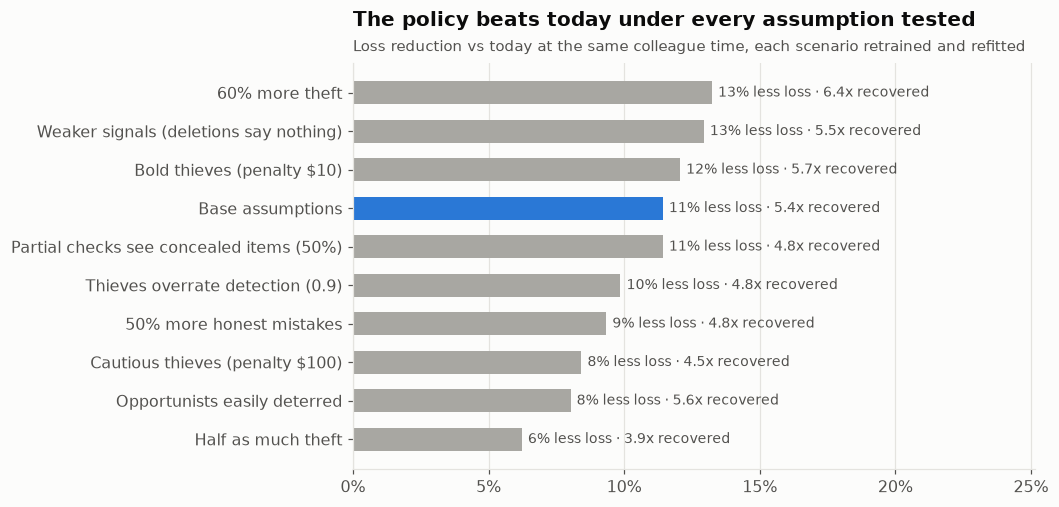

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.8))
d = sens.sort_values('loss reduction')
colors = [BLUE if i == 'Base assumptions' else GREY for i in d.index]
bars = ax.barh(d.index, d['loss reduction'], color=colors, height=0.6)
ax.bar_label(bars, labels=[f"{v:.0%} less loss · {m:.1f}x recovered" for v, m in zip(d['loss reduction'], d['recovery multiple'])],
             padding=4, color=TEXT_2, fontsize=9)
ax.xaxis.set_major_formatter(pct())
ax.set_xlim(0, d['loss reduction'].max() * 1.9)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_title('The policy beats today under every assumption tested')
subtitle(ax, 'Loss reduction vs today at the same colleague time, each scenario retrained and refitted')
save(fig, '19_sensitivity')
fig

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Same colleague time as today: 12% less loss (range over runs ±0.4%), 5.6x as much recovered (\$11 to \$59 per colleague hour) and 69% fewer honest shoppers stopped | **The headline** |
| 2 | Averaging what targeted rescans find overstates total loss nearly 4x; inverse-probability weighting is unbiased (within 1%) with about ±9% error per period; the random floor alone is unbiased but noisier (±15%) | Log every rescan's probability; report loss with weighting, keep the floor as the check |
| 3 | In every one of ten stress tests the policy beats today: loss 6–13% lower, recovery 3.9–6.4x, honest stops down 69–70% | The conclusion does not hinge on one assumption |
| 4 | It matters least when there is little theft (6%) or when thieves are cautious (8%): today's flat 12% rescan rate deters cautious thieves, and targeting gives up some of that | The trade-off a store should know about; the random floor is the lever if deterrence matters more |
| 5 | Randomising beats a plain threshold by at most 1.4% in any scenario; judging a policy against static shoppers overstates its recovery by 20–52% in every scenario | Detection, not deterrence, drives the result; always evaluate against shoppers who respond |

**What this does not show.** Everything is measured against a calibrated simulator, so these are
claims that the method recovers the known truth, not forecasts of Sainsbury's loss. The live test
that would settle it is a randomised trial by store (business case, week 10).